# From Click to Checkout: Mapping the Customer Journey with a Sankey Diagram

**Author:** Pham Hong Hieu (Haven) · **Data:** an online stuffed-toy retailer, March 2012 to March 2015: 472,871 sessions,
1,188,124 page views and 32,313 orders

## The question

Marketing and web teams each see one piece of the journey: marketing sees traffic sources, the web team sees landing
pages, and finance sees orders. This analysis joins the three into one picture:

**traffic source → landing page → outcome (which product was bought, or no purchase)**

It then answers the questions the picture raises:

1. Which traffic sources reach which landing pages, and how much of each flow ends in an order?
2. Which landing pages convert best, **on a fair comparison**?
3. What should change in traffic routing and landing-page strategy?

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "figure.dpi": 110})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
sessions = pd.read_csv(DATA_DIR / "website_sessions.csv.gz", parse_dates=["created_at"])
pageviews = pd.read_csv(DATA_DIR / "website_pageviews.csv.gz", parse_dates=["created_at"])
orders = pd.read_csv(DATA_DIR / "orders.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
print(f"Sessions {len(sessions):,} | page views {len(pageviews):,} | orders {len(orders):,}")

Sessions 472,871 | page views 1,188,124 | orders 32,313


## 2. Building one row per journey

- **Landing page:** the first page viewed in each session (lowest page-view ID).
- **Traffic source:** `utm_source` for paid traffic. Untagged sessions are split with `http_referer` into
  *organic search* (came from a search engine) and *direct type-in* (no referrer). They are kept in the flow rather than
  dropped, so every stage of the diagram covers every session.
- **Outcome:** the primary product of the order placed in the session, or *No purchase*.

In [3]:
landing = (pageviews.sort_values("website_pageview_id").groupby("website_session_id")
           .agg(landing_page=("pageview_url", "first")))
journey = (sessions.set_index("website_session_id")
           .join(landing, validate="one_to_one")
           .join(orders.set_index("website_session_id")[["primary_product_id"]], validate="one_to_one"))
journey["source"] = journey["utm_source"].fillna(
    journey["http_referer"].notna().map({True: "organic search", False: "direct type-in"}))
journey["outcome"] = journey["primary_product_id"].map(products.set_index("product_id")["product_name"]).fillna("No purchase")
journey["converted"] = journey["primary_product_id"].notna()

assert len(journey) == len(sessions) and journey["landing_page"].notna().all()
assert journey["converted"].sum() == len(orders)
print(f"Journeys: {len(journey):,} | converting: {journey['converted'].sum():,} ({journey['converted'].mean():.2%})")
journey[["source", "utm_campaign", "device_type", "landing_page", "outcome"]].head()

Journeys: 472,871 | converting: 32,313 (6.83%)


,source,utm_campaign,device_type,landing_page,outcome
website_session_id,,,,,
1,gsearch,nonbrand,mobile,/home,No purchase
2,gsearch,nonbrand,desktop,/home,No purchase
3,gsearch,nonbrand,desktop,/home,No purchase
4,gsearch,nonbrand,desktop,/home,No purchase
5,gsearch,nonbrand,mobile,/home,No purchase


## 3. The journey map

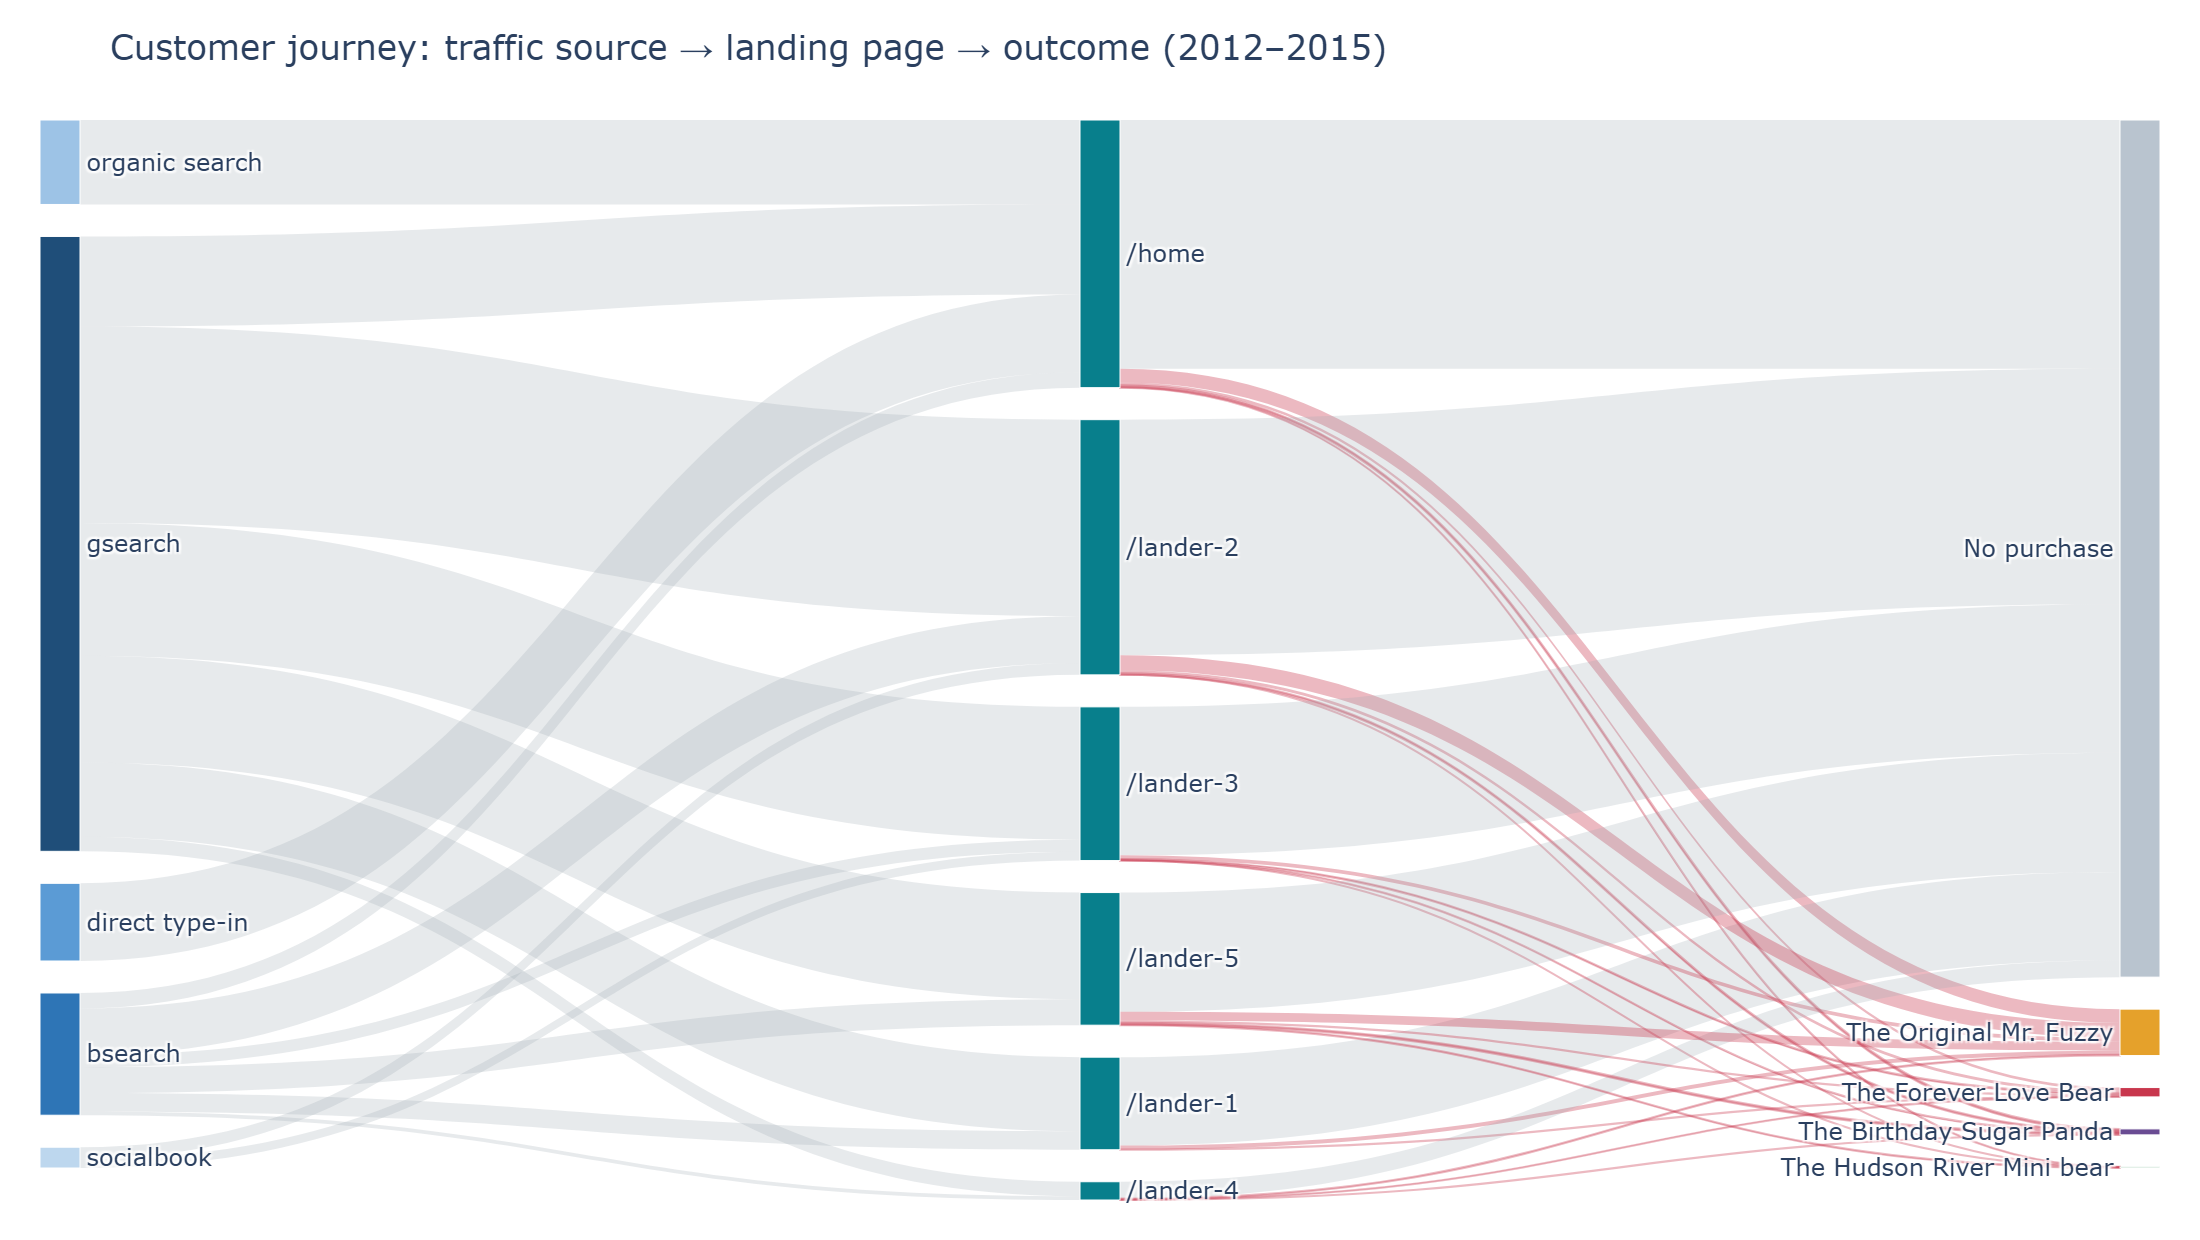

In [4]:
stage1 = journey.groupby(["source", "landing_page"]).size().reset_index(name="value")
stage2 = journey.groupby(["landing_page", "outcome"]).size().reset_index(name="value")
stage1.columns = stage2.columns = ["from", "to", "value"]
flows = pd.concat([stage1, stage2], ignore_index=True)

sources = journey["source"].value_counts().index.tolist()
pages = journey["landing_page"].value_counts().index.tolist()
outcomes = [o for o in journey["outcome"].value_counts().index if o != "No purchase"] + ["No purchase"]
nodes = sources + pages + outcomes
index = {name: i for i, name in enumerate(nodes)}
colours = (["#1F4E79", "#2E75B6", "#9DC3E6", "#5B9BD5", "#BDD7EE"][:len(sources)]
           + ["#087F8C"] * len(pages)
           + ["#E5A12B", "#C8374D", "#6A4C93", "#2E8B57"][:len(outcomes) - 1] + ["#B9C4CF"])
link_colours = ["rgba(200,55,77,0.35)" if t != "No purchase" and t in outcomes else "rgba(160,170,180,0.25)"
                for t in flows["to"]]

sankey = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=nodes, color=colours, pad=16, thickness=20, line=dict(color="white", width=0.5)),
    link=dict(source=flows["from"].map(index), target=flows["to"].map(index), value=flows["value"],
              color=link_colours),
))
sankey.update_layout(title="Customer journey: traffic source → landing page → outcome (2012–2015)",
                     font=dict(size=12), width=1100, height=620, margin=dict(l=20, r=20, t=60, b=20))
sankey.write_image(FIG_DIR / "01_journey_sankey.png", scale=2)
sankey.write_html(Path("../reports") / "journey_sankey.html", include_plotlyjs="cdn")
display(Image(str(FIG_DIR / "01_journey_sankey.png")))

The map shows how traffic is routed. `/home` receives **all** brand and untagged traffic (organic search, direct
type-in and brand-campaign clicks), while the `/lander-*` pages receive only paid non-brand traffic. About 93% of
sessions end in *No purchase*, and Mr. Fuzzy dominates the purchase side. An interactive version is saved as
`reports/journey_sankey.html`.

## 4. Conversion by source

In [5]:
by_source = (journey.groupby(["source", "utm_campaign"], dropna=False)
             .agg(sessions=("converted", "size"), orders=("converted", "sum"), conversion_pct=("converted", "mean")))
by_source["conversion_pct"] *= 100
by_source = by_source.sort_values("sessions", ascending=False)
by_source.to_csv(TABLE_DIR / "conversion_by_source.csv")
by_source

sessions  orders  conversion_pct
source         utm_campaign                                      
gsearch        nonbrand            282706   18822            6.66
bsearch        nonbrand             54909    3818            6.95
organic search NaN                  43411    3262            7.51
direct type-in NaN                  39917    2856            7.15
gsearch        brand                33329    2511            7.53
bsearch        brand                 7914     701            8.86
socialbook     desktop_targeted      5590     288            5.15
               pilot                 5095      55            1.08

Sources convert within a narrow band of 6.7–8.9%, except the two social campaigns. Brand search converts best,
because these visitors already know what they want. The `socialbook` pilot campaign converts at about 1%.

## 5. Which landing page converts best?

A raw ranking of landing pages is misleading for three reasons:

1. **Different traffic.** `/home` receives brand and untagged traffic, while the landers receive non-brand paid
   clicks.
2. **Different devices.** `/lander-3` serves only mobile visitors, and mobile converts far below desktop.
3. **Different periods.** The landers were tested one after another, and the whole site converted better each year.

In [6]:
pages_summary = (journey.groupby("landing_page")
                 .agg(first_seen=("created_at", "min"), last_seen=("created_at", "max"),
                      sessions=("converted", "size"), conversion_pct=("converted", "mean"),
                      mobile_share=("device_type", lambda d: (d == "mobile").mean())))
pages_summary["conversion_pct"] *= 100
pages_summary["mobile_share"] *= 100
pages_summary["first_seen"] = pages_summary["first_seen"].dt.date
pages_summary["last_seen"] = pages_summary["last_seen"].dt.date
pages_summary.to_csv(TABLE_DIR / "landing_pages.csv")
pages_summary

,first_seen,last_seen,sessions,conversion_pct,mobile_share
landing_page,,,,,
/home,2012-03-19,2015-03-19,137576,7.06,36.57
/lander-1,2012-06-19,2013-03-10,47574,4.53,21.26
/lander-2,2013-01-14,2014-12-27,131170,7.72,4.89
/lander-3,2013-07-09,2015-03-19,79000,3.39,100.00
/lander-4,2014-02-02,2014-04-19,9385,7.54,0.00
/lander-5,2014-08-02,2015-03-19,68166,10.17,0.00


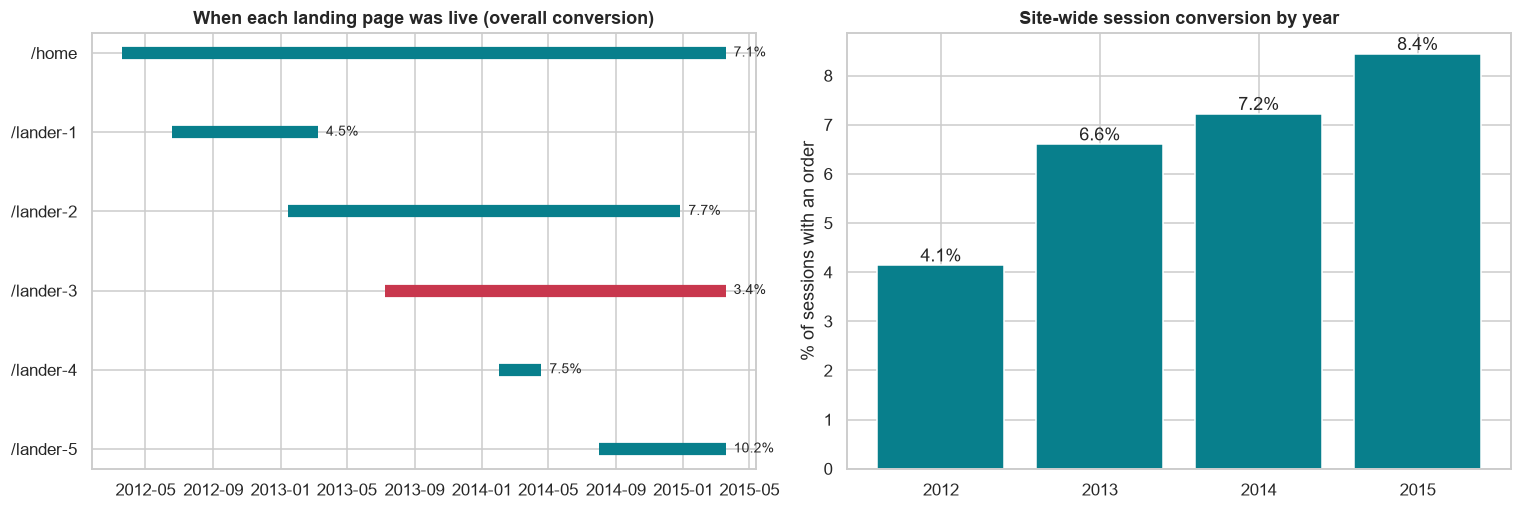

In [7]:
yearly = journey.groupby(journey["created_at"].dt.year)["converted"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
active = pages_summary.reset_index()
for i, row in active.iterrows():
    axes[0].plot([pd.Timestamp(row["first_seen"]), pd.Timestamp(row["last_seen"])], [i, i], linewidth=8,
                 color="#087F8C" if row["mobile_share"] < 50 else "#C8374D", solid_capstyle="butt")
    axes[0].text(pd.Timestamp(row["last_seen"]), i, f"  {row['conversion_pct']:.1f}%", va="center", fontsize=9)
axes[0].set_yticks(range(len(active)), active["landing_page"])
axes[0].set(title="When each landing page was live (overall conversion)", xlabel="")
axes[0].invert_yaxis()
axes[1].bar(yearly.index.astype(str), yearly.values, color="#087F8C")
for x, y in zip(yearly.index.astype(str), yearly.values):
    axes[1].text(x, y, f"{y:.1f}%", ha="center", va="bottom")
axes[1].set(title="Site-wide session conversion by year", ylabel="% of sessions with an order")
fig.tight_layout()
save(fig, "02_landing_timeline_and_trend")
plt.show()

The left panel shows that the landers ran in sequence: `/lander-1` in 2012, `/lander-2` from 2013, and `/lander-5`
from August 2014. Red marks the mobile-only `/lander-3`. The right panel shows that site-wide conversion doubled
between 2012 and 2015. A lander introduced late therefore looks better partly because the whole site had improved.

### A fair comparison: same period, same traffic, same device

From 2 August to 27 December 2014, `/lander-2` and `/lander-5` both served desktop non-brand traffic, and
`/lander-3` served mobile non-brand traffic.

In [8]:
window = journey[(journey["created_at"] >= "2014-08-02") & (journey["created_at"] < "2014-12-28")
                 & (journey["utm_campaign"] == "nonbrand")
                 & journey["landing_page"].isin(["/lander-2", "/lander-3", "/lander-5"])]
fair = (window.groupby(["device_type", "landing_page"])
        .agg(sessions=("converted", "size"), orders=("converted", "sum"), conversion_pct=("converted", "mean")))
fair["conversion_pct"] *= 100

desktop = window[window["device_type"] == "desktop"]
p2 = desktop.loc[desktop["landing_page"] == "/lander-2", "converted"]
p5 = desktop.loc[desktop["landing_page"] == "/lander-5", "converted"]
diff = p5.mean() - p2.mean()
se = np.sqrt(p5.mean() * (1 - p5.mean()) / len(p5) + p2.mean() * (1 - p2.mean()) / len(p2))
fair.to_csv(TABLE_DIR / "fair_lander_comparison.csv")
display(fair)
print(f"/lander-5 vs /lander-2 (desktop): {diff * 100:+.2f} pp, 95% CI [{(diff - 1.96 * se) * 100:+.2f}, {(diff + 1.96 * se) * 100:+.2f}] pp")

sessions  orders  conversion_pct
device_type landing_page                                  
desktop     /lander-2        14501    1214            8.37
            /lander-5        36103    3591            9.95
mobile      /lander-3        21681     746            3.44

/lander-5 vs /lander-2 (desktop): +1.57 pp, 95% CI [+1.03, +2.12] pp


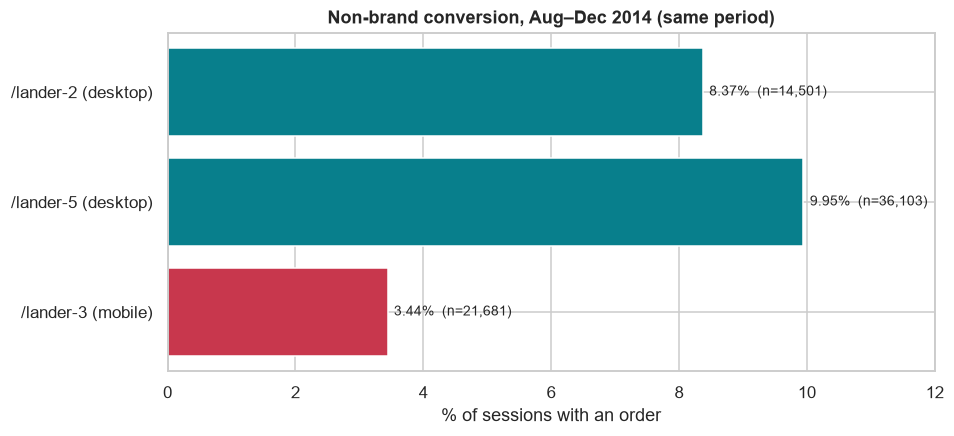

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = fair.reset_index()
plot["label"] = plot["landing_page"] + " (" + plot["device_type"] + ")"
bars = ax.barh(plot["label"], plot["conversion_pct"], color=["#C8374D" if d == "mobile" else "#087F8C" for d in plot["device_type"]])
for bar, value, n in zip(bars, plot["conversion_pct"], plot["sessions"]):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2, f"{value:.2f}%  (n={n:,})", va="center", fontsize=9)
ax.set(title="Non-brand conversion, Aug–Dec 2014 (same period)", xlabel="% of sessions with an order", xlim=(0, 12))
ax.invert_yaxis()
save(fig, "03_fair_lander_comparison")
plt.show()

On a like-for-like basis, `/lander-5` converts better than `/lander-2` for desktop non-brand traffic, by about
1.6 percentage points (roughly 19% in relative terms), and the confidence interval excludes zero. `/lander-3`'s low
rate is a mobile problem rather than a page problem: it is the only page mobile non-brand visitors reach.

## 6. Does the landing page change *what* people buy?

In [10]:
mix = (journey[journey["converted"]].groupby("landing_page")["outcome"].value_counts(normalize=True)
       .unstack(fill_value=0) * 100)
mix.round(1)

outcome,The Birthday Sugar Panda,The Forever Love Bear,The Hudson River Mini bear,The Original Mr. Fuzzy
landing_page,,,,
/home,10.30,15.00,1.90,72.80
/lander-1,0.00,4.30,0.00,95.70
/lander-2,7.80,15.20,0.00,76.90
/lander-3,9.30,17.60,2.20,71.00
/lander-4,13.80,20.80,0.00,65.40
/lander-5,13.40,15.80,4.90,66.00


The product mix varies by landing page mainly because the pages ran at different times, before or after each
product launched. The pages that were live after the later launches (`/lander-4`, `/lander-5`, `/lander-3` and
`/home`) show a broader mix. The landing page routes traffic, but product availability determines what is bought.

## 7. Recommendations

1. **Roll `/lander-5` out to all desktop non-brand traffic.** It beats `/lander-2` by about 1.6 pp in a fair
   same-period comparison.
2. **Prioritise mobile.** Mobile non-brand traffic converts at about 3.4%, roughly a third of desktop. A mobile
   version of the best lander, tested against `/lander-3`, is the largest single opportunity in the journey.
3. **Stop or redesign the `socialbook` pilot.** It converts at about 1%.
4. **Judge future landing-page tests by concurrent A/B splits, not by comparing periods.** Site-wide conversion rose
   every year, so sequential tests overstate new pages.

## 8. Limitations

- Attribution is per session and last-touch. Visitors who return later to buy are counted as non-converting in
  earlier sessions.
- The fair comparison covers one five-month window and one traffic type. Results for brand or mobile traffic may
  differ.
- The data are a public, fictional training dataset.